# Rockburst paper: one-click experiments + Overleaf bundle
**Run the cells top to bottom.** Only cell 4 needs your input (upload the dataset). At the end you download `overleaf_bundle.zip`, upload it to Overleaf, compile `main.tex`, and every number, table and figure is filled in.

**Dataset:** Li et al. (2023), *Sustainability* 15(18):13282, doi 10.3390/su151813282 -> MDPI paper page -> *Supplementary Materials* -> download the data file (csv or xlsx).

In [25]:
# 1. install libraries (about 1 minute)
!pip -q install xgboost lightgbm shap openpyxl

In [26]:
%%writefile rockburst_experiments.py
#!/usr/bin/env python3
"""
Rockburst intensity prediction: leakage-free repeated nested cross-validation,
6 classifiers x 3 imbalance strategies, Wilcoxon tests, bootstrap CI,
learning curve, permutation importance, SHAP.

Writes everything the LaTeX paper needs into --outdir:
  auto_macros.tex, tables/*.tex, figures/*.jpg, summary.csv, folds.csv
Usage:
  python rockburst_experiments.py --data rockburst.csv            (target = last column)
  python rockburst_experiments.py --data rockburst.xlsx --target "Rockburst grade"
  python rockburst_experiments.py --demo --quick                  (code test only, fake data)
"""
import argparse, os, sys, time, warnings, platform, collections
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy import stats
from joblib import Parallel, delayed
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, GridSearchCV, StratifiedShuffleSplit
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score, matthews_corrcoef,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
SEED = 42
STRATS = ["none", "smote", "weights"]
STRAT_TXT = {"none": "no resampling", "smote": "SMOTE", "weights": "class weights"}
STRAT_NAME = {"none": "No resampling", "smote": "SMOTE", "weights": "Class weights"}
KNOWN_ORDER = ["none", "no", "nil", "light", "slight", "weak", "low", "moderate", "medium",
               "strong", "intense", "severe", "high", "violent", "heavy"]


def tex(s):
    s = str(s)
    for a, b in [("\\", "/"), ("_", r"\_"), ("%", r"\%"), ("&", r"\&"), ("#", r"\#"), ("$", r"\$")]:
        s = s.replace(a, b)
    return s


# --------------------------------------------------------------------------- SMOTE + wrapper
def smote(X, y, k, seed):
    rng = np.random.RandomState(seed)
    classes, counts = np.unique(y, return_counts=True)
    nmax = counts.max()
    Xs, ys = [X], [y]
    for c, n in zip(classes, counts):
        if n == nmax or n < 2:
            continue
        Xc = X[y == c]
        kk = min(k, n - 1)
        d = ((Xc[:, None, :] - Xc[None, :, :]) ** 2).sum(-1)
        np.fill_diagonal(d, np.inf)
        nn = np.argsort(d, axis=1)[:, :kk]
        m = nmax - n
        i = rng.randint(0, n, m)
        j = nn[i, rng.randint(0, kk, m)]
        lam = rng.rand(m, 1)
        Xs.append(Xc[i] + lam * (Xc[j] - Xc[i]))
        ys.append(np.full(m, c))
    return np.vstack(Xs), np.concatenate(ys)


class Strat(BaseEstimator, ClassifierMixin):
    """Applies an imbalance strategy inside fit() so it only ever sees training data."""
    def __init__(self, base=None, mode="none", k=5, seed=SEED):
        self.base = base; self.mode = mode; self.k = k; self.seed = seed

    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y)
        self.base_ = clone(self.base)
        self.classes_ = np.unique(y)
        if self.mode == "smote":
            X, y = smote(X, y, self.k, self.seed)
            self.base_.fit(X, y)
        elif self.mode == "sw":
            self.base_.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
        else:
            self.base_.fit(X, y)
        return self

    def predict(self, X):
        return self.base_.predict(np.asarray(X, float))

    def predict_proba(self, X):
        return self.base_.predict_proba(np.asarray(X, float))


def models():
    return collections.OrderedDict([
        ("LR", (LogisticRegression(max_iter=3000, random_state=SEED), {"C": [0.1, 1, 10]}, True)),
        ("SVM", (SVC(kernel="rbf", random_state=SEED), {"C": [1, 10], "gamma": ["scale", 0.1]}, True)),
        ("RF", (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1),
                {"max_depth": [None, 8], "min_samples_leaf": [1, 2]}, True)),
        ("XGBoost", (XGBClassifier(n_estimators=150, random_state=SEED, eval_metric="mlogloss",
                                   verbosity=0, n_jobs=1),
                     {"max_depth": [3, 5], "learning_rate": [0.05, 0.1]}, True)),
        ("LightGBM", (LGBMClassifier(n_estimators=150, random_state=SEED, verbose=-1, n_jobs=1,
                                     min_child_samples=5),
                      {"num_leaves": [8, 16], "learning_rate": [0.05, 0.1]}, True)),
        ("MLP", (MLPClassifier(max_iter=1500, random_state=SEED),
                 {"hidden_layer_sizes": [(16,), (32, 16)], "alpha": [1e-3, 1e-2]}, False)),
    ])


MODELS = models()
TREE_MODELS = ["RF", "XGBoost", "LightGBM"]


def build(name, strat):
    est, grid, _ = MODELS[name]
    est = clone(est)
    mode = "none"
    if strat == "smote":
        mode = "smote"
    elif strat == "weights":
        if name == "XGBoost":
            mode = "sw"
        else:
            est.set_params(class_weight="balanced")
    pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                     ("clf", Strat(est, mode))])
    pg = {"clf__base__" + k: v for k, v in grid.items()}
    return pipe, pg


def configs():
    out = []
    for m in MODELS:
        for s in STRATS:
            if s == "weights" and not MODELS[m][2]:
                continue
            out.append((m, s))
    return out


def metrics(yt, yp):
    return dict(f1=f1_score(yt, yp, average="macro"), acc=accuracy_score(yt, yp),
                bacc=balanced_accuracy_score(yt, yp), mcc=matthews_corrcoef(yt, yp))


def run_fold(m, s, fid, tr, te, X, y, inner):
    pipe, pg = build(m, s)
    gs = GridSearchCV(pipe, pg, cv=StratifiedKFold(inner, shuffle=True, random_state=SEED),
                      scoring="f1_macro", n_jobs=1, refit=True)
    gs.fit(X[tr], y[tr])
    yp = gs.predict(X[te])
    r = dict(model=m, strat=s, fold=fid, te=te, yp=yp, params=gs.best_params_)
    r.update(metrics(y[te], yp))
    return r


def perm_fold(m, s, params, tr, te, X, y, nrep, seed):
    pipe, _ = build(m, s)
    pipe.set_params(**params).fit(X[tr], y[tr])
    pi = permutation_importance(pipe, X[te], y[te], scoring="f1_macro", n_repeats=nrep, random_state=seed)
    return pi.importances_mean


# --------------------------------------------------------------------------- data
def load(path, target):
    if path.lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, keep_default_na=False, na_values=["", "NA", "N/A", "NaN", "nan", "?", "-"])
    else:
        df = pd.read_csv(path, keep_default_na=False, na_values=["", "NA", "N/A", "NaN", "nan", "?", "-"])
    df.columns = [str(c).strip() for c in df.columns]
    t = target if target else df.columns[-1]
    if t not in df.columns:
        sys.exit("Target column '%s' not found. Columns: %s" % (t, list(df.columns)))
    return df, t


def prepare(df, t, order):
    df = df.copy()
    df = df[df[t].notna()]
    lab = df[t].astype(str).str.strip()
    if order:
        classes = [c.strip() for c in order.split(",")]
    else:
        uniq = list(pd.unique(lab))
        try:
            classes = [str(v) for v in sorted(uniq, key=lambda v: float(v))]
        except ValueError:
            kn = [k for k in KNOWN_ORDER if k in [u.lower() for u in uniq]]
            if len(kn) == len(uniq):
                classes = sorted(uniq, key=lambda u: KNOWN_ORDER.index(u.lower()))
            else:
                classes = sorted(uniq)
    # tolerate "1.0" vs "1"
    def norm(v):
        try:
            f = float(v); return str(int(f)) if f == int(f) else str(f)
        except ValueError:
            return v
    lab = lab.map(norm)
    classes = [norm(c) for c in classes]
    keep = lab.isin(classes)
    if (~keep).any():
        print("WARNING: dropping %d rows with labels not in class order" % (~keep).sum())
    df, lab = df[keep], lab[keep]
    feats = []
    for c in df.columns:
        if c == t:
            continue
        x = pd.to_numeric(df[c], errors="coerce")
        if x.notna().sum() >= 0.5 * len(x) and x.nunique() > 1:
            df[c] = x; feats.append(c)
        else:
            print("Skipping non-numeric/ID column:", c)
    y = lab.map({c: i for i, c in enumerate(classes)}).values.astype(int)
    return df[feats].reset_index(drop=True), y, classes, feats


def demo_data():
    from sklearn.datasets import make_classification
    X, y = make_classification(n_samples=300, n_features=8, n_informative=5, n_redundant=2, n_classes=4,
                               weights=[.12, .3, .38, .2], class_sep=0.8, random_state=1)
    names = ["MTS", "UCS", "UTS", "SCF", "B1", "B2", "Wet", "Depth"]
    df = pd.DataFrame(X, columns=names)
    df.iloc[np.random.RandomState(0).choice(300, 30, replace=False), 7] = np.nan
    df["Level"] = pd.Series(y).map({0: "None", 1: "Light", 2: "Moderate", 3: "Strong"})
    return df


# --------------------------------------------------------------------------- figures
def savefig(fig, path):
    fig.savefig(path, dpi=300, bbox_inches="tight", pil_kwargs={"quality": 95})
    plt.close(fig)


def box(ax, x, y, w, h, txt, fc="#dbeafe", ec="#1e3a8a", fs=7):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.05", fc=fc, ec=ec, lw=1))
    ax.text(x + w / 2, y + h / 2, txt, ha="center", va="center", fontsize=fs, wrap=True)


def arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="-|>", color="#1e3a8a", lw=1))


def fig_workflow(path):
    fig, ax = plt.subplots(figsize=(7.2, 3.0)); ax.set_xlim(0, 10); ax.set_ylim(0, 4.2); ax.axis("off")
    top = ["Rockburst\ndatabase", "Outer fold:\ntrain / test\nsplit", "Median\nimputation\n+ scaling", "Imbalance\nstrategy\n(none/SMOTE/weights)"]
    bot = ["Inner 3-fold\ngrid search\n(macro-F1)", "Refit on outer\ntraining set", "Evaluate once on\nouter test fold", "Metrics, Wilcoxon,\nbootstrap CI,\nlearning curve,\nSHAP"]
    for i, t in enumerate(top):
        box(ax, 0.2 + i * 2.5, 2.7, 2.0, 1.2, t, fc="#dbeafe")
        if i < 3: arrow(ax, 2.2 + i * 2.5, 3.3, 2.7 + i * 2.5, 3.3)
    for i, t in enumerate(bot):
        box(ax, 0.2 + i * 2.5, 0.5, 2.0, 1.4, t, fc="#dcfce7", ec="#166534")
        if i < 3: arrow(ax, 2.2 + i * 2.5, 1.2, 2.7 + i * 2.5, 1.2)
    arrow(ax, 8.2, 2.7, 1.2, 1.9)
    ax.text(5, 0.1, "Steps in the shaded outer training set only; test data is never touched during tuning",
            ha="center", fontsize=6.5, style="italic")
    savefig(fig, path)


def fig_nested(path):
    fig, ax = plt.subplots(figsize=(7.2, 3.2)); ax.set_xlim(0, 10); ax.set_ylim(0, 5); ax.axis("off")
    ax.text(0.1, 4.6, "Outer loop: repeated stratified 5-fold (3 repeats = 15 outer folds)", fontsize=8, weight="bold")
    for i in range(5):
        c = "#fca5a5" if i == 2 else "#bfdbfe"
        box(ax, 0.2 + i * 1.9, 3.5, 1.8, 0.7, "Test fold" if i == 2 else "Train", fc=c, ec="#444")
    ax.text(0.1, 2.9, "Inner loop on the outer training set: stratified 3-fold grid search", fontsize=8, weight="bold")
    for i in range(3):
        c = "#fde68a" if i == 1 else "#bbf7d0"
        box(ax, 0.2 + i * 3.1, 1.9, 3.0, 0.7, "Validation" if i == 1 else "Inner train", fc=c, ec="#444")
    ax.text(0.1, 1.3, "Impute, scale, SMOTE and hyper-parameter search are fitted inside the inner/outer training data only.",
            fontsize=7)
    ax.text(0.1, 0.8, "Best setting (highest mean macro-F1) is refitted on the whole outer training set,\n"
                      "then evaluated once on the outer test fold.", fontsize=7)
    savefig(fig, path)


# --------------------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--data"); ap.add_argument("--data2")
    ap.add_argument("--target"); ap.add_argument("--class-order", default="")
    ap.add_argument("--outdir", default="outputs")
    ap.add_argument("--jobs", type=int, default=-1)
    ap.add_argument("--demo", action="store_true"); ap.add_argument("--quick", action="store_true")
    a = ap.parse_args()
    t0 = time.time()
    out = a.outdir
    for d in (out, out + "/figures", out + "/tables"):
        os.makedirs(d, exist_ok=True)
    FIG = lambda n: out + "/figures/" + n + ".jpg"
    TAB = lambda n: out + "/tables/" + n + ".tex"

    if a.demo:
        df, tcol = demo_data(), "Level"
        order = a.class_order or "None,Light,Moderate,Strong"
    else:
        if not a.data:
            sys.exit("Give --data file.csv (or use --demo to test the code)")
        df, tcol = load(a.data, a.target)
        order = a.class_order
    Xdf, y, classes, feats = prepare(df, tcol, order)
    X = Xdf.values.astype(float)
    N, P, K = X.shape[0], X.shape[1], len(classes)
    cnt = np.bincount(y, minlength=K)
    print("Samples %d, features %d, classes %s, counts %s" % (N, P, classes, cnt.tolist()))
    print("Features:", feats)
    if cnt.min() < 5:
        print("WARNING: smallest class has %d samples; folds are reduced." % cnt.min())
    n_out = int(min(5, cnt.min())); n_rep = 1 if a.quick else 3
    inner = 3 if cnt.min() >= 5 else 2
    nfolds = n_out * n_rep
    outer = list(RepeatedStratifiedKFold(n_splits=n_out, n_repeats=n_rep, random_state=SEED).split(X, y))

    fig_nested(FIG("fig_nested_cv"))   # Fig. 1 (workflow) is your own image: figures/fig_workflow.jpg

    cfgs = configs()
    print("%d configurations x %d outer folds ..." % (len(cfgs), nfolds))
    tasks = [(m, s, i, tr, te) for (m, s) in cfgs for i, (tr, te) in enumerate(outer)]
    res = Parallel(n_jobs=a.jobs, verbose=5)(delayed(run_fold)(m, s, i, tr, te, X, y, inner)
                                             for (m, s, i, tr, te) in tasks)
    R = collections.defaultdict(list)
    for r in res:
        R[(r["model"], r["strat"])].append(r)
    for k in R:
        R[k].sort(key=lambda r: r["fold"])

    def arr(k, met):
        return np.array([r[met] for r in R[k]])
    summ = []
    for k in cfgs:
        row = dict(model=k[0], strategy=k[1])
        for met in ("f1", "acc", "bacc", "mcc"):
            row[met + "_mean"] = arr(k, met).mean(); row[met + "_sd"] = arr(k, met).std(ddof=1)
        summ.append(row)
    S = pd.DataFrame(summ); S.to_csv(out + "/summary.csv", index=False)
    pd.DataFrame([{k: v for k, v in r.items() if k not in ("te", "yp", "params")} | {"params": str(r["params"])}
                  for r in res]).to_csv(out + "/folds.csv", index=False)
    best = max(cfgs, key=lambda k: arr(k, "f1").mean())
    bm, bs = best
    print("BEST:", best, arr(best, "f1").mean())

    def pooled(k):
        yt = np.concatenate([y[r["te"]] for r in R[k]]); yp = np.concatenate([r["yp"] for r in R[k]])
        return yt, yp
    yt, yp = pooled(best)

    # ---- tables: metric matrices
    def matrix_table(met, name, bold_best=True):
        L = [r"\begin{tabular}{lccc}", r"\hline", "Model & No resampling & SMOTE & Class weights \\\\", r"\hline"]
        bk = max(cfgs, key=lambda k: arr(k, met).mean())
        for m in MODELS:
            cells = []
            for s in STRATS:
                if (m, s) not in R:
                    cells.append("n/a"); continue
                c = "%.3f $\\pm$ %.3f" % (arr((m, s), met).mean(), arr((m, s), met).std(ddof=1))
                cells.append(r"\textbf{%s}" % c if (m, s) == bk and bold_best else c)
            L.append("%s & %s \\\\" % (m, " & ".join(cells)))
        L += [r"\hline", r"\end{tabular}"]
        open(TAB(name), "w").write("\n".join(L))
    for met, nm in [("f1", "tab_f1"), ("acc", "tab_acc"), ("bacc", "tab_bacc"), ("mcc", "tab_mcc")]:
        matrix_table(met, nm)

    # grids
    L = [r"\begin{tabular}{lp{2.35in}}", r"\hline", "Model & Grid searched \\\\", r"\hline"]
    for m, (_, g, _) in MODELS.items():
        L.append("%s & %s \\\\" % (m, "; ".join("%s $\\in$ \\{%s\\}" % (tex(k), ", ".join(
            "None" if v is None else tex(v) for v in vals)) for k, vals in g.items())))
    L += [r"\hline", r"\end{tabular}"]
    open(TAB("tab_grids"), "w").write("\n".join(L))

    # classes
    L = [r"\begin{tabular}{lrr}", r"\hline", "Class & Cases & Share (\\%) \\\\", r"\hline"]
    for i, c in enumerate(classes):
        L.append("%s & %d & %.1f \\\\" % (tex(c), cnt[i], 100 * cnt[i] / N))
    L += [r"\hline", "Total & %d & 100.0 \\\\" % N, r"\hline", r"\end{tabular}"]
    open(TAB("tab_classes"), "w").write("\n".join(L))

    # descriptive
    L = [r"\begin{tabular}{lrrrrr}", r"\hline", "Indicator & Valid & Mean & SD & Min & Max \\\\", r"\hline"]
    for f in feats:
        x = Xdf[f]
        L.append("%s & %d & %.2f & %.2f & %.2f & %.2f \\\\" % (tex(f), x.notna().sum(), x.mean(), x.std(), x.min(), x.max()))
    L += [r"\hline", r"\end{tabular}"]
    open(TAB("tab_dataset"), "w").write("\n".join(L))

    # per-class (best, pooled)
    pr, rc, f1c, sup = precision_recall_fscore_support(yt, yp, labels=list(range(K)), zero_division=0)
    L = [r"\begin{tabular}{lrrrr}", r"\hline", "Class & Precision & Recall & F1 & Support \\\\", r"\hline"]
    for i, c in enumerate(classes):
        L.append("%s & %.3f & %.3f & %.3f & %d \\\\" % (tex(c), pr[i], rc[i], f1c[i], sup[i]))
    L += [r"\hline", r"\end{tabular}"]
    open(TAB("tab_perclass"), "w").write("\n".join(L))

    # Wilcoxon
    bf = arr(best, "f1"); wl = []
    for k in cfgs:
        if k == best: continue
        d = bf - arr(k, "f1")
        try:
            W, p = stats.wilcoxon(bf, arr(k, "f1"))
        except ValueError:
            W, p = 0.0, 1.0
        wl.append((k, d.mean(), W, p))
    wl.sort(key=lambda z: -arr(z[0], "f1").mean())
    nsig = sum(1 for z in wl if z[3] < 0.05)
    L = [r"\begin{tabular}{lrrr}", r"\hline", "Compared with & $\\Delta$F1 & $W$ & $p$ \\\\", r"\hline"]
    for k, dm, W, p in wl[:6]:
        ps = "$<$0.001" if p < 0.001 else "%.3f" % p
        L.append("%s + %s & %.3f & %.1f & %s \\\\" % (k[0], STRAT_NAME[k[1]], dm, W, ps))
    L += [r"\hline", r"\end{tabular}"]
    open(TAB("tab_wilcoxon"), "w").write("\n".join(L))

    # ---- bootstrap CI
    rng = np.random.RandomState(SEED)
    bs_f1 = [f1_score(yt[i], yp[i], average="macro") for i in (rng.randint(0, len(yt), len(yt)) for _ in range(1000))]
    lo, hi = np.percentile(bs_f1, [2.5, 97.5])

    # ---- figures: data
    f, ax = plt.subplots(figsize=(3.4, 2.4))
    ax.bar([tex(c).replace("\\", "") for c in classes], cnt, color="#3b82f6")
    for i, v in enumerate(cnt): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("Cases"); ax.set_xlabel("Rockburst intensity class"); savefig(f, FIG("fig_class_dist"))

    C = Xdf.corr(method="spearman").values
    f, ax = plt.subplots(figsize=(3.6, 3.2)); im = ax.imshow(C, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(P)); ax.set_yticks(range(P)); ax.set_xticklabels(feats, rotation=60, ha="right", fontsize=6)
    ax.set_yticklabels(feats, fontsize=6)
    for i in range(P):
        for j in range(P): ax.text(j, i, "%.2f" % C[i, j], ha="center", va="center", fontsize=5)
    f.colorbar(im, ax=ax, fraction=0.046); savefig(f, FIG("fig_corr"))

    nc = min(P, 4); nr = int(np.ceil(P / nc))
    f, axs = plt.subplots(nr, nc, figsize=(7.2, 1.9 * nr)); axs = np.atleast_1d(axs).ravel()
    for j, ft in enumerate(feats):
        axs[j].boxplot([Xdf[ft][y == k].dropna() for k in range(K)], showfliers=False)
        axs[j].set_xticks(range(1, K + 1)); axs[j].set_xticklabels([str(c)[:4] for c in classes])
        axs[j].set_title(ft, fontsize=7); axs[j].tick_params(labelsize=6)
    for j in range(P, len(axs)): axs[j].axis("off")
    f.tight_layout(); savefig(f, FIG("fig_feature_boxplots"))

    # ---- figures: results
    H = np.full((len(MODELS), 3), np.nan)
    for i, m in enumerate(MODELS):
        for j, s in enumerate(STRATS):
            if (m, s) in R: H[i, j] = arr((m, s), "f1").mean()
    f, ax = plt.subplots(figsize=(3.4, 2.6)); im = ax.imshow(H, cmap="YlGnBu")
    ax.set_xticks(range(3)); ax.set_xticklabels([STRAT_NAME[s] for s in STRATS], fontsize=6, rotation=15)
    ax.set_yticks(range(len(MODELS))); ax.set_yticklabels(list(MODELS), fontsize=7)
    for i in range(len(MODELS)):
        for j in range(3): ax.text(j, i, "n/a" if np.isnan(H[i, j]) else "%.3f" % H[i, j], ha="center", va="center", fontsize=7)
    f.colorbar(im, ax=ax, fraction=0.046); savefig(f, FIG("fig_heatmap_f1"))

    f, ax = plt.subplots(figsize=(3.4, 4.2))
    ax.boxplot([arr(k, "f1") for k in cfgs], orientation="horizontal", showfliers=True)
    ax.set_yticks(range(1, len(cfgs) + 1)); ax.set_yticklabels(["%s/%s" % (k[0], k[1]) for k in cfgs])
    ax.tick_params(labelsize=6); ax.set_xlabel("Macro-F1 over outer folds"); ax.invert_yaxis(); savefig(f, FIG("fig_boxplot_f1"))

    cm = confusion_matrix(yt, yp, labels=list(range(K))); cmn = cm / cm.sum(1, keepdims=True).clip(1)
    f, axs = plt.subplots(1, 2, figsize=(7.2, 3.0))
    for ax, M, fmt, ttl in [(axs[0], cm, "%d", "Counts"), (axs[1], cmn, "%.2f", "Recall (row-normalised)")]:
        ax.imshow(M, cmap="Blues"); ax.set_title(ttl, fontsize=8)
        ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels(classes, fontsize=7); ax.set_yticklabels(classes, fontsize=7)
        ax.set_xlabel("Predicted", fontsize=7); ax.set_ylabel("True", fontsize=7)
        for i in range(K):
            for j in range(K): ax.text(j, i, fmt % M[i, j], ha="center", va="center", fontsize=8,
                                       color="white" if M[i, j] > M.max() / 2 else "black")
    f.tight_layout(); savefig(f, FIG("fig_cm_best"))
    mis = yt != yp
    neigh = 100 * np.mean(np.abs(yt[mis] - yp[mis]) == 1) if mis.any() else 100.0

    # ---- modal params of best config (for learning curve and SHAP)
    def modal(k):
        c = collections.Counter(repr(sorted(r["params"].items(), key=lambda z: z[0])) for r in R[k])
        top = c.most_common(1)[0][0]
        for r in R[k]:
            if repr(sorted(r["params"].items(), key=lambda z: z[0])) == top: return r["params"]
    bparams = modal(best)

    # ---- learning curve
    fr = [0.3, 0.5, 0.7, 1.0] if a.quick else [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
    lcf = list(RepeatedStratifiedKFold(n_splits=n_out, n_repeats=2, random_state=SEED + 1).split(X, y))

    def lc_one(frac, tr, te):
        trs = tr
        if frac < 1:
            try:
                trs = tr[next(StratifiedShuffleSplit(1, train_size=frac, random_state=SEED).split(tr, y[tr]))[0]]
            except ValueError:
                trs = np.random.RandomState(SEED).choice(tr, max(int(frac * len(tr)), K * 2), replace=False)
        p, _ = build(bm, bs); p.set_params(**bparams).fit(X[trs], y[trs])
        return len(trs), f1_score(y[te], p.predict(X[te]), average="macro")
    lcr = Parallel(n_jobs=a.jobs)(delayed(lc_one)(fc, tr, te) for fc in fr for tr, te in lcf)
    lcr = np.array(lcr).reshape(len(fr), len(lcf), 2)
    lc_n = lcr[:, :, 0].mean(1); lc_m = lcr[:, :, 1].mean(1); lc_s = lcr[:, :, 1].std(1, ddof=1)
    f, ax = plt.subplots(figsize=(3.4, 2.5)); ax.plot(lc_n, lc_m, "o-", color="#1d4ed8")
    ax.fill_between(lc_n, lc_m - lc_s, lc_m + lc_s, alpha=0.25); ax.set_xlabel("Training samples")
    ax.set_ylabel("Test macro-F1"); ax.grid(alpha=.3); savefig(f, FIG("fig_learning_curve"))
    gain = lc_m[-1] - lc_m[0]
    trend = "was still rising" if lc_m[-1] - lc_m[-2] > 0.01 else "had largely levelled off"

    # ---- permutation importance (best config, outer test folds)
    pis = Parallel(n_jobs=a.jobs)(delayed(perm_fold)(bm, bs, R[best][i]["params"], outer[i][0], outer[i][1], X, y, 10 if a.quick else 20, SEED)
                                  for i in range(nfolds))
    pimp = np.mean(pis, 0); psd = np.std(pis, 0)
    o = np.argsort(pimp)[::-1]
    f, ax = plt.subplots(figsize=(3.4, 2.6)); ax.barh([feats[i] for i in o][::-1], pimp[o][::-1], xerr=psd[o][::-1], color="#0ea5e9")
    ax.tick_params(labelsize=7); ax.set_xlabel("Drop in macro-F1"); savefig(f, FIG("fig_perm_importance"))

    # ---- SHAP
    sm = bm if bm in TREE_MODELS else max([k for k in cfgs if k[0] in TREE_MODELS], key=lambda k: arr(k, "f1").mean())[0]
    ss = bs if bm in TREE_MODELS else max([k for k in cfgs if k[0] in TREE_MODELS], key=lambda k: arr(k, "f1").mean())[1]
    shap_params = modal((sm, ss))
    import shap
    sp, _ = build(sm, ss); sp.set_params(**shap_params).fit(X, y)
    Xt = sp[:-1].transform(X); fnames = list(Xdf.columns)
    sv = shap.TreeExplainer(sp.named_steps["clf"].base_).shap_values(Xt)
    if isinstance(sv, list): sv = np.stack(sv, -1)
    sv = np.asarray(sv)
    if sv.ndim == 3 and sv.shape[0] == K and sv.shape[1] == Xt.shape[0]: sv = np.transpose(sv, (1, 2, 0))
    ma = np.abs(sv).mean(0)  # (f, K)
    tot = ma.sum(1); oo = np.argsort(tot)[::-1]
    f, ax = plt.subplots(figsize=(3.4, 2.8)); left = np.zeros(P)
    cols = plt.cm.viridis(np.linspace(0.1, 0.9, K))
    for k in range(K):
        ax.barh([fnames[i] for i in oo][::-1], ma[oo, k][::-1], left=left, color=cols[k], label=str(classes[k]))
        left += ma[oo, k][::-1]
    ax.set_xlabel("Mean |SHAP value|"); ax.tick_params(labelsize=7); ax.legend(fontsize=6); savefig(f, FIG("fig_shap_bar"))
    plt.figure(figsize=(3.6, 3.0))
    shap.summary_plot(sv[:, :, K - 1], Xt, feature_names=fnames, show=False, max_display=10, plot_size=None)
    plt.gcf().savefig(FIG("fig_shap_beeswarm"), dpi=300, bbox_inches="tight", pil_kwargs={"quality": 95}); plt.close("all")
    cl = []
    for j in oo[:3]:
        rho = stats.spearmanr(Xt[:, j], sv[:, j, K - 1])[0]
        eff = "raised" if rho > 0.2 else ("lowered" if rho < -0.2 else "had no clear monotonic effect on")
        cl.append("higher %s %s the SHAP contribution towards the %s class ($\\rho$ = %.2f)" % (tex(fnames[j]), eff, tex(classes[-1]), rho))
    shap_sentence = "In the SHAP analysis of %s with %s, %s." % (sm, STRAT_TXT[ss], "; ".join(cl))

    # ---- second dataset
    second = ""
    if a.data2 and not a.demo:
        d2, t2 = load(a.data2, a.target)
        X2df, y2, c2, f2 = prepare(d2, t2, ",".join(classes))
        common = [f for f in feats if f in f2]
        if len(common) >= 3:
            pp, _ = build(bm, bs); idx = [feats.index(f) for f in common]
            pp.set_params(**bparams).fit(X[:, idx], y); pr2 = pp.predict(X2df[common].values.astype(float))
            m2 = metrics(y2, pr2)
            second = ("In the cross-database test, the best configuration trained on the main database and applied to a second "
                      "database of %d cases (%d common indicators) reached a macro-F1 of %.3f and an accuracy of %.3f." %
                      (len(y2), len(common), m2["f1"], m2["acc"]))

    # ---- auto sentences
    sm_mean = {s: np.mean([arr(k, "f1").mean() for k in cfgs if k[1] == s]) for s in STRATS}
    sev = K - 1
    rec = {}
    for s in STRATS:
        if (bm, s) in R:
            ty, tp = pooled((bm, s)); rec[s] = recall = ((tp[ty == sev] == sev).mean() if (ty == sev).any() else float("nan"))
    imb = ("Averaged over the classifiers, macro-F1 was %.3f without resampling, %.3f with SMOTE and %.3f with class weights. "
           "For %s, the recall of the %s class was %s." % (
               sm_mean["none"], sm_mean["smote"], sm_mean["weights"], bm, tex(classes[sev]),
               ", ".join("%.2f (%s)" % (rec[s], STRAT_TXT[s]) for s in STRATS if s in rec)))
    sig = ("The best configuration differed significantly ($p<0.05$) from %d of the %d other configurations in a paired Wilcoxon "
           "test over outer folds." % (nsig, len(wl)))
    miss = Xdf.isna().sum(); tm = int(miss.sum())
    if tm == 0:
        misstxt = "the database contained no missing values"
    else:
        top = miss[miss > 0].sort_values(ascending=False)
        misstxt = "%d of %d values (%.1f\\%%) were missing, mainly in %s" % (
            tm, N * P, 100 * tm / (N * P), ", ".join("%s (%d)" % (tex(i), v) for i, v in top.head(3).items()))
    mem = ""
    try:
        mem = "%.0f GB RAM" % (int([l for l in open("/proc/meminfo") if l.startswith("MemTotal")][0].split()[1]) / 1e6)
    except Exception:
        pass
    machine = "%s, %d logical CPU cores%s" % (tex(platform.processor() or platform.machine()), os.cpu_count(), (", " + mem) if mem else "")
    import sklearn, xgboost, lightgbm
    big, small = int(np.argmax(cnt)), int(np.argmin(cnt))
    pm = lambda a_: (a_.mean(), a_.std(ddof=1))
    f1m, f1s = pm(arr(best, "f1")); am, as_ = pm(arr(best, "acc"))
    M = {
        "Ncases": N, "Nfeat": P, "Nclass": K, "NConfigs": len(cfgs), "NFolds": nfolds,
        "ClassList": ", ".join(tex(c) for c in classes[:-1]) + " and " + tex(classes[-1]),
        "FeatList": ", ".join(tex(f) for f in feats[:-1]) + " and " + tex(feats[-1]),
        "MissText": misstxt,
        "BestModel": bm, "BestStrat": STRAT_TXT[bs],
        "BestF": "%.3f" % f1m, "BestFsd": "%.3f" % f1s, "BestAcc": "%.3f" % am, "BestAccsd": "%.3f" % as_,
        "BestBacc": "%.3f" % arr(best, "bacc").mean(), "BestMcc": "%.3f" % arr(best, "mcc").mean(),
        "CIlo": "%.3f" % lo, "CIhi": "%.3f" % hi,
        "FeatA": tex(feats[o[0]]), "FeatB": tex(feats[o[1]]), "FeatC": tex(feats[o[2]]),
        "ShapFeatA": tex(fnames[oo[0]]), "ShapFeatB": tex(fnames[oo[1]]), "ShapFeatC": tex(fnames[oo[2]]),
        "ShapModel": "%s with %s" % (sm, STRAT_TXT[ss]),
        "NeighPct": "%.0f" % neigh, "SevClass": tex(classes[sev]),
        "SevRecall": "%.2f" % rc[sev], "SevPrec": "%.2f" % pr[sev],
        "BigClass": tex(classes[big]), "BigN": cnt[big], "SmallClass": tex(classes[small]), "SmallN": cnt[small],
        "ImbRatio": "%.1f" % (cnt[big] / cnt[small]),
        "LCstartF": "%.3f" % lc_m[0], "LCendF": "%.3f" % lc_m[-1], "LCstartN": "%d" % lc_n[0], "LCendN": "%d" % lc_n[-1],
        "LCgain": "%+.3f" % gain, "LCtrend": trend,
        "AutoImbalance": imb, "AutoSig": sig, "ShapSentence": shap_sentence, "SecondText": second,
        "RunMin": "%.0f" % ((time.time() - t0) / 60), "Machine": machine,
        "PyVer": platform.python_version(), "SkVer": sklearn.__version__, "XgbVer": xgboost.__version__,
        "LgbVer": lightgbm.__version__, "ShapVer": shap.__version__, "NpVer": np.__version__, "PdVer": pd.__version__,
        "DemoNote": "\\textbf{SYNTHETIC DEMO DATA - NOT REAL RESULTS}" if a.demo else "",
    }
    with open(out + "/auto_macros.tex", "w") as fh:
        for k, v in M.items():
            fh.write("\\newcommand{\\%s}{%s}\n" % (k, v))
    S.round(4).to_csv(out + "/summary.csv", index=False)
    print("\nDONE in %.1f min. Best: %s / %s  macro-F1 %.3f +- %.3f" % ((time.time() - t0) / 60, bm, bs, f1m, f1s))
    print("Top permutation features:", [feats[i] for i in o[:3]])


if __name__ == "__main__":
    main()


Overwriting rockburst_experiments.py


In [27]:
%%writefile main.tex
\documentclass[conference]{IEEEtran}
\usepackage{cite}
\usepackage{amsmath,amssymb,amsfonts}
\usepackage{graphicx}
\usepackage{array}
\usepackage[T1]{fontenc}
\usepackage{textcomp}

% ---- safe inclusion of generated figures / tables (never a fatal error) ----
\newsavebox{\tabbox}
\newcommand{\safefig}[2]{%
  \IfFileExists{figures/#1}%
   {\safefig{figures/#1}{#2}}%
   {\fbox{\parbox{0.8\columnwidth}{\centering\small Figure file \detokenize{#1} not found. Upload the figures/ folder.}}}}
\newcommand{\safetable}[1]{%
  \IfFileExists{tables/#1.tex}%
   {\sbox{\tabbox}{\input{tables/#1.tex}}%
    \ifdim\wd\tabbox>\columnwidth\resizebox{\columnwidth}{!}{\usebox{\tabbox}}\else\usebox{\tabbox}\fi}%
   {\fbox{\parbox{0.8\columnwidth}{\centering\small Table file \detokenize{#1}.tex not found. Upload the tables/ folder.}}}}

% ---- numbers written by the experiment script (auto_macros.tex) ----
\InputIfFileExists{auto_macros.tex}{}{\typeout{auto_macros.tex not found - using default placeholders}}
% defaults, used only when auto_macros.tex does not define them
\newcommand{\ph}[1]{\textbf{[#1]}}
\providecommand{\Ncases}{\ph{N}}
\providecommand{\Nfeat}{\ph{p}}
\providecommand{\Nclass}{\ph{K}}
\providecommand{\NConfigs}{17}
\providecommand{\NFolds}{15}
\providecommand{\ClassList}{\ph{class names}}
\providecommand{\FeatList}{\ph{indicator names}}
\providecommand{\MissText}{\ph{missing-value summary}}
\providecommand{\BestModel}{\ph{best model}}
\providecommand{\BestStrat}{\ph{strategy}}
\providecommand{\BestF}{\ph{F1}}
\providecommand{\BestFsd}{\ph{sd}}
\providecommand{\BestAcc}{\ph{acc}}
\providecommand{\BestAccsd}{\ph{sd}}
\providecommand{\BestBacc}{\ph{bacc}}
\providecommand{\BestMcc}{\ph{mcc}}
\providecommand{\CIlo}{\ph{lo}}
\providecommand{\CIhi}{\ph{hi}}
\providecommand{\FeatA}{\ph{feature 1}}
\providecommand{\FeatB}{\ph{feature 2}}
\providecommand{\FeatC}{\ph{feature 3}}
\providecommand{\ShapFeatA}{\ph{feature 1}}
\providecommand{\ShapFeatB}{\ph{feature 2}}
\providecommand{\ShapFeatC}{\ph{feature 3}}
\providecommand{\ShapModel}{\ph{model}}
\providecommand{\NeighPct}{\ph{x}}
\providecommand{\SevClass}{\ph{class}}
\providecommand{\SevRecall}{\ph{recall}}
\providecommand{\SevPrec}{\ph{precision}}
\providecommand{\BigClass}{\ph{class}}
\providecommand{\BigN}{\ph{n}}
\providecommand{\SmallClass}{\ph{class}}
\providecommand{\SmallN}{\ph{n}}
\providecommand{\ImbRatio}{\ph{r}}
\providecommand{\LCstartF}{\ph{F1}}
\providecommand{\LCendF}{\ph{F1}}
\providecommand{\LCstartN}{\ph{n}}
\providecommand{\LCendN}{\ph{n}}
\providecommand{\LCgain}{\ph{change}}
\providecommand{\LCtrend}{\ph{trend}}
\providecommand{\AutoImbalance}{\ph{imbalance summary}}
\providecommand{\AutoSig}{\ph{significance summary}}
\providecommand{\ShapSentence}{}
\providecommand{\SecondText}{}
\providecommand{\RunMin}{\ph{min}}
\providecommand{\Machine}{\ph{computer}}
\providecommand{\PyVer}{\ph{ver}}
\providecommand{\SkVer}{\ph{ver}}
\providecommand{\XgbVer}{\ph{ver}}
\providecommand{\LgbVer}{\ph{ver}}
\providecommand{\ShapVer}{\ph{ver}}
\providecommand{\NpVer}{\ph{ver}}
\providecommand{\PdVer}{\ph{ver}}
\providecommand{\DemoNote}{}

\begin{document}

\title{Explainable Machine Learning for Rockburst Intensity Prediction: Handling Class Imbalance and Small-Sample Uncertainty with Nested Cross-Validation}

\author{\IEEEauthorblockN{Siby Lalachan}
\IEEEauthorblockA{Department of Computer Science and Engineering\\
Lovely Professional University, Phagwara, Punjab, India\\
siby.lalachan@lpu.in}}

\maketitle

\begin{abstract}
Rockburst is a sudden, violent release of elastic strain energy from hard rock around underground openings and remains a serious hazard in deep mining and tunnelling. Machine learning is widely used to predict rockburst intensity from a small set of geomechanical indicators, but many studies are weakened by databases of only a few hundred cases, unequal class frequencies, black-box models, and performance estimates obtained from the same data that were used to tune the models. This paper presents a leakage-free, reproducible evaluation framework for rockburst intensity classification. Six classifiers (logistic regression, support vector machine, random forest, XGBoost, LightGBM and a multilayer perceptron) are combined with three imbalance strategies (no resampling, SMOTE and class weights), giving \NConfigs{} configurations because the MLP was not evaluated with class weights. They are assessed with repeated stratified nested cross-validation on a public database of \Ncases{} cases with \Nfeat{} indicators and \Nclass{} intensity classes. Results are reported as mean $\pm$ standard deviation of accuracy, macro-F1, balanced accuracy and the Matthews correlation coefficient over \NFolds{} outer folds, and differences are tested with the Wilcoxon signed-rank test. A learning curve and bootstrap confidence intervals quantify small-sample uncertainty, and permutation importance and SHAP explain the predictions in mining-engineering terms. The best configuration was \BestModel{} with \BestStrat{}, with a macro-F1 of \BestF{} $\pm$ \BestFsd{} and an accuracy of \BestAcc{} $\pm$ \BestAccsd{}. The most influential indicators were \FeatA, \FeatB{} and \FeatC. The code is fully reproducible and can be reused for other small geotechnical databases. \DemoNote
\end{abstract}

\begin{IEEEkeywords}
rockburst prediction, mining safety, class imbalance, SMOTE, nested cross-validation, explainable machine learning, SHAP
\end{IEEEkeywords}

\section{Introduction}
Rockburst is a dynamic failure of brittle rock in which elastic strain energy accumulated around an underground opening is suddenly released, ejecting rock fragments into the excavation. It is typically associated with deep, high-stress hard-rock environments such as deep metal and coal mines, hydropower tunnels and underground caverns. The consequences include injury and loss of life, damage to equipment and support systems, production stoppages and, in severe cases, the abandonment of a working area. As mining and tunnelling move to greater depths, where in-situ stresses are higher, more projects are exposed to this hazard, and reliable early-warning tools are of direct importance for mine safety \cite{r11,r12}.

Because the mechanism depends on the interaction of stress, rock strength, rock-mass structure, stored energy and excavation geometry, it is difficult to describe with a single closed-form law. Prediction practice has therefore relied on empirical proneness indices (based on stress--strength ratios, brittleness indices and energy indices), numerical simulation, and field monitoring such as microseismic systems \cite{r1,r13}. Empirical indices are simple but are usually calibrated on a limited number of cases and transfer poorly between sites, numerical models need detailed site parameters that are hard to obtain, and monitoring reports a hazard only once it is developing. Data-driven classification offers a complementary route: a model learns the relationship between a few easily measured indicators and the observed rockburst intensity from historical case records \cite{r1,r3}. Support vector machines, neural networks, decision trees, ensembles and, more recently, boosting and deep-learning models have been applied to rockburst data with high reported accuracies \cite{r2,r3,r5}. Nevertheless, three practical issues limit the reliability and the engineering usefulness of the results.
\begin{enumerate}
\item \emph{Small samples.} Public rockburst databases usually contain only a few hundred cases compiled from many projects. A single train--test split then gives an unstable performance estimate, and apparent differences between classifiers may be sampling noise.
\item \emph{Class imbalance.} Intensity classes are rarely equally frequent. Strong rockbursts, the most dangerous, are typically among the least represented, so a classifier can achieve a high overall accuracy while missing the events that matter most \cite{r4,r6}.
\item \emph{Optimistic validation and opacity.} Hyper-parameters are often tuned and evaluated on the same data, which inflates performance \cite{r21,r22}, and few studies explain why a model predicts a given intensity, which limits engineers' trust \cite{r4,r8}.
\end{enumerate}
This paper addresses these issues in a single consistent framework. The main contributions are:
\begin{itemize}
\item a leakage-free evaluation protocol based on repeated stratified nested cross-validation, in which imputation, scaling, resampling and hyper-parameter search are performed only on the training data of each fold;
\item a systematic comparison of six classifiers under three imbalance strategies (no resampling, SMOTE and class weights) using imbalance-aware metrics and statistical tests;
\item a quantification of small-sample uncertainty through fold-to-fold variability, bootstrap confidence intervals and a learning curve;
\item an explainability analysis with SHAP and out-of-fold permutation importance, interpreted in terms of rock mechanics; and
\item fully reproducible code, with an optional cross-database generalisation test.
\end{itemize}
The remainder of the paper is organised as follows. Section~II reviews related work, Section~III describes the methodology, Section~IV details the experimental set-up and data analysis, Section~V presents and discusses the results, and Section~VI concludes.

\section{Literature Review}
Research on rockburst prediction is extensive; recent reviews summarise empirical, numerical, monitoring-based and artificial-intelligence approaches \cite{r11,r12,r13}. This section focuses on studies published since 2023 that are most relevant to the three issues raised above: ensemble and boosting models, imbalance handling, and explainability.

\subsection{Empirical Criteria and Review Studies}
Classical rockburst prediction relies on indices that compare the stress around an opening with rock strength, on brittleness measures and on elastic energy indices. Li et al.\ point out that such indices usually capture only one aspect of the phenomenon and are formulated for particular engineering cases, which limits their transferability to other geological conditions \cite{r1}. Comprehensive reviews of machine-learning-based prediction distinguish long-term prediction, which uses intrinsic rock properties and stress state, from short-term prediction, which uses monitoring data such as microseismic events \cite{r11,r12}. A scientometric review of 2449 papers and a detailed analysis of 336 key studies further show how fast the field is growing and how fragmented the methods are \cite{r13}.

\subsection{Ensemble and Boosting Methods}
Ensembles are the dominant approach for long-term intensity classification. Wang et al.\ compared stacking and voting integration of several base learners and found that, in most cases, they outperformed the ordinary individual models, and that the choice of fusion strategy materially affects performance \cite{r2}. Jia et al.\ combined seven individual classifiers (including XGBoost, SVM, MLP, $k$-nearest neighbours and random forest) in a soft-voting ensemble whose weights were optimised with a metaheuristic and five-fold cross-validation; the ensemble was 4.4\% more accurate than the best single classifier, and the elastic energy index was the most important variable \cite{r3}. Li et al.\ built a voting ensemble of five learners, tuned with the tree-structured Parzen estimator, on a 344-case database with eight indicators, and found the elastic energy index, maximum tangential stress and uniaxial compressive strength to be the most important features \cite{r1}. Shen et al.\ proposed an Optuna-tuned random forest combined with isolation forest outlier handling and SMOTE, and explained it with Shapley values \cite{r7}. These studies demonstrate that tree-based and ensemble methods are strong on small tabular rockburst data, but most of them evaluate performance on a single hold-out split or use cross-validation also for tuning.

\subsection{Deep and Short-Term Monitoring-Based Models}
For monitoring data, Qiu and Zhou developed an ensemble model optimised with the L\'evy-flight Jaya algorithm and five-fold cross-validation on microseismic records from a hydropower diversion tunnel, and analysed it with SHAP and LIME, finding that cumulative released energy, the number of microseismic events and cumulative apparent volume were influential \cite{r9}. Wang et al.\ coupled convolutional and recurrent networks for microseismic-based short-term prediction and used SHAP to verify interpretability \cite{r10}. Such deep models need larger and more homogeneous data than the few hundred static cases usually available for long-term prediction, so they are not considered further here.

\subsection{Class Imbalance in Rockburst Data}
Synthetic minority over-sampling (SMOTE) \cite{r15} creates new minority samples by interpolation between neighbouring minority points. Xiao et al.\ applied SMOTE to a database from four deep gold mines with seven indicators; a stacking model of extremely randomised trees and logistic regression performed best, and SMOTE improved the prediction of weak rockburst \cite{r5}. Rao et al.\ studied shallow rockbursts (burial depth below 500~m) with a small imbalanced dataset and compared six oversampling techniques with several classifiers; an extra-trees model with SVM-SMOTE reached 93.75\% accuracy and the oversampling reduced overfitting \cite{r6}. Lin et al.\ used a variational autoencoder to generate minority samples for 537 records with four indicators and compared it with SMOTE, SMOTE-ENN and SMOTE-Tomek combined with gradient-boosting models \cite{r4}. Several of these studies report very high accuracies, up to 100\% on small evaluation sets \cite{r5}, which motivates repeated and nested validation rather than a single split. Moreover, Li et al.\ note that class definitions differ between data sources and that many cases lie on the border between neighbouring classes, so label noise is an additional limitation \cite{r1}.

\subsection{Explainable Machine Learning}
SHAP \cite{r18} attributes each prediction to the input features using Shapley values from cooperative game theory. Lin et al.\ combined feature sensitivity analysis, TreeSHAP and Anchor to explain a VAE-NGBoost rockburst model \cite{r4}. Ibrahim et al.\ coupled SHAP with adaptive conformal prediction on XGBoost to provide both explanations and valid uncertainty estimates, arguing that earlier work focused too much on accuracy and too little on explainability and uncertainty \cite{r8}. Reported importance rankings broadly agree that energy- and stress-related indicators matter most \cite{r1,r3}, but they are derived from models fitted and evaluated in different ways.

\subsection{Validation Practice with Small Data}
Selecting hyper-parameters and estimating performance on the same cross-validation folds gives optimistically biased estimates \cite{r21,r22}. Nested cross-validation removes this bias at a higher computational cost, which is affordable for a few hundred samples. Statistical tests such as the Wilcoxon signed-rank test \cite{r23,r24} help separate real differences from noise.

\subsection{Summary and Research Gap}
Table~\ref{tab:lit} summarises representative studies. Among the studies reviewed here, imbalance handling, explanation and uncertainty are addressed separately, and tuning and evaluation commonly share the same data. This work combines (i) leakage-free nested validation, (ii) a controlled comparison of three imbalance strategies across six model families, (iii) explicit small-sample uncertainty analysis and (iv) engineering-oriented explanation within one reproducible framework.

\begin{table}[!t]
\caption{Summary of representative recent studies on rockburst intensity prediction.}
\label{tab:lit}
\centering\scriptsize
\renewcommand{\arraystretch}{1.05}
\begin{tabular}{@{}p{0.2in}p{1.45in}p{0.65in}p{0.75in}@{}}
\hline
Ref. & Main approach & Imbalance & Explanation\\ \hline
\cite{r1} & Voting ensemble, relabelling, TPE tuning (344 cases) & -- & Feature importance\\
\cite{r2} & Stacking and voting ensembles & -- & --\\
\cite{r3} & Soft voting of 7 classifiers, metaheuristic weights & -- & Feature importance\\
\cite{r4} & VAE oversampling + gradient boosting (537 cases) & VAE vs.\ SMOTE variants & TreeSHAP, Anchor\\
\cite{r5} & SMOTE + stacking, four gold mines & SMOTE & Sensitivity\\
\cite{r6} & Six oversamplers, shallow rockburst & Six methods & --\\
\cite{r7} & Optuna random forest, isolation forest & SMOTE & Shapley\\
\cite{r8} & XGBoost with conformal prediction & -- & SHAP\\
Ours & 6 models $\times$ 3 strategies, nested CV, learning curve & 3 strategies & SHAP + permutation\\ \hline
\end{tabular}
\end{table}

\section{Methodology}
\subsection{Problem Formulation}
Let $\mathcal{D}=\{(\mathbf{x}_i,y_i)\}_{i=1}^{N}$ be a rockburst database, where $\mathbf{x}_i\in\mathbb{R}^{p}$ contains $p$ geomechanical indicators and $y_i\in\{1,\dots,K\}$ is the ordered intensity class. The aim is to learn a classifier $f:\mathbb{R}^{p}\to\{1,\dots,K\}$ that generalises to unseen cases. Fig.~\ref{fig:workflow} summarises the workflow: the database is pre-processed and analysed with Spearman correlation, evaluated with repeated stratified outer cross-validation and an inner grid search, combined with an imbalance strategy and one of six classifiers, and finally assessed with metrics, statistical tests and explainability methods.

\begin{figure*}[!t]
\centering\safefig{fig_workflow.jpg}{0.88\textwidth}
\caption{Overall experimental workflow of the proposed framework. Median imputation and standardisation are re-fitted on the training part of every fold, so no test information enters the model.}
\label{fig:workflow}
\end{figure*}

\subsection{Dataset}
The data come from the open rockburst database compiled by Li et al.\ \cite{r1} from published cases worldwide and released as supplementary material of their paper. This study uses \Ncases{} cases with \Nfeat{} numerical indicators and \Nclass{} ordered intensity classes (\ClassList). The indicators are \FeatList; they are summarised in Table~\ref{tab:dataset}. Among them, the maximum tangential stress $\sigma_\theta$ (MPa) around the opening, the uniaxial compressive strength $\sigma_c$ and tensile strength $\sigma_t$ of the rock (MPa), the stress concentration factor $\mathrm{SCF}=\sigma_\theta/\sigma_c$, the brittleness indices $B_1=\sigma_c/\sigma_t$ and $B_2=(\sigma_c-\sigma_t)/(\sigma_c+\sigma_t)$, the elastic energy index $W_{et}$ (ratio of elastic energy to plastic dissipated energy) and the burial depth are the quantities most commonly used in the rockburst literature. Regarding missing data, \MissText. As discussed by Li et al., the intensity labels were assigned by different authors with different criteria, so some label noise is unavoidable \cite{r1}.

\subsection{Pre-processing}
Missing numerical values were replaced by the column median, with the median estimated only from the training portion of each fold. Features were then standardised, $z=(x-\mu)/s$, again using $\mu$ and $s$ estimated only from the training portion so that no information from test samples enters the model. Standardisation is essential for distance-based and gradient-based learners (SVM, logistic regression, MLP and SMOTE) and harmless for tree-based models. No samples were removed as outliers, because extreme stress and strength values are physically meaningful in rockburst data. Imputation, scaling and resampling were implemented inside a single estimator so that they are re-fitted automatically for every training set, in both the outer and inner loops.

\subsection{Classifiers}
Six classifiers from different model families were compared. \emph{Logistic regression} (LR) models class probabilities with the softmax function
\begin{equation}
P(y=k\mid\mathbf{x})=\frac{\exp(\mathbf{w}_k^{\top}\mathbf{x}+b_k)}{\sum_{j=1}^{K}\exp(\mathbf{w}_j^{\top}\mathbf{x}+b_j)},
\end{equation}
with L2 regularisation controlled by $C$. The \emph{support vector machine} (SVM) \cite{r20} uses a radial-basis-function kernel
\begin{equation}
k(\mathbf{x},\mathbf{x}')=\exp\!\left(-\gamma\lVert\mathbf{x}-\mathbf{x}'\rVert^{2}\right),
\end{equation}
where $\gamma$ and the penalty $C$ are tuned. \emph{Random forest} (RF) \cite{r14} averages many decision trees trained on bootstrap samples with random feature subsets, which reduces variance. \emph{XGBoost} \cite{r16} builds trees additively by minimising a regularised objective
\begin{equation}
\mathcal{L}=\sum_i \ell(y_i,\hat y_i)+\sum_m \Omega(h_m),\quad \Omega(h)=\gamma T+\tfrac{1}{2}\lambda\lVert\mathbf{w}\rVert^{2},
\end{equation}
where $T$ is the number of leaves of tree $h_m$. \emph{LightGBM} \cite{r17} is a gradient-boosting framework with histogram-based, leaf-wise tree growth that is efficient on small and large tables. The \emph{multilayer perceptron} (MLP) is a feed-forward network with hidden layers $\mathbf{h}=\sigma(\mathbf{W}\mathbf{x}+\mathbf{b})$ and a softmax output, trained with cross-entropy loss and L2 penalty $\alpha$. Small networks were used because of the limited sample size.

\subsection{Class-Imbalance Strategies}
Three strategies were compared. (i)~\emph{No resampling} is the baseline. (ii)~\emph{SMOTE} \cite{r15} generates synthetic samples for each minority class until it matches the majority class. For a minority sample $\mathbf{x}_i$ and one of its $k=5$ nearest minority neighbours $\mathbf{x}_{nn}$ (fewer if the class is very small), a new sample is
\begin{equation}
\mathbf{x}_{\text{new}}=\mathbf{x}_i+\lambda(\mathbf{x}_{nn}-\mathbf{x}_i),\quad \lambda\sim U(0,1).
\end{equation}
SMOTE was implemented directly, applied after scaling and inside the training part of every fold; validation and test data were never resampled. (iii)~\emph{Class weights} penalise errors on rare classes more heavily by weighting class $c$ with
\begin{equation}
w_c=\frac{N}{K\,n_c},
\end{equation}
where $n_c$ is the number of training samples of class $c$. Class weights were applied through the \texttt{class\_weight} option, or through sample weights for XGBoost. The MLP implementation does not support weights, so this combination was not evaluated, which leaves \NConfigs{} configurations in total.

\subsection{Repeated Nested Cross-Validation}
To obtain an unbiased estimate of generalisation performance, a repeated stratified 5-fold outer loop (repeated 3 times with different shuffles, giving \NFolds{} outer folds) was combined with a stratified 3-fold inner loop (Fig.~\ref{fig:nested}). For every outer training set, the inner loop performs a grid search over the hyper-parameters in Table~\ref{tab:grids} and selects the setting with the highest mean macro-F1. The selected model is refitted on the whole outer training set and evaluated once on the outer test fold. Stratification preserves the class proportions in every fold, which is essential for small and imbalanced data.

\begin{figure}[!t]
\centering\safefig{fig_nested_cv.jpg}{\columnwidth}
\caption{Nested cross-validation scheme. Imputation, scaling, SMOTE and hyper-parameter search are confined to the training data.}
\label{fig:nested}
\end{figure}

\subsection{Evaluation Metrics}
Let $TP_k$, $FP_k$, $FN_k$ denote the true positives, false positives and false negatives of class $k$. Accuracy is the proportion of correct predictions. Because accuracy is dominated by frequent classes, the following imbalance-aware metrics are also reported:
\begin{equation}
F1_k=\frac{2TP_k}{2TP_k+FP_k+FN_k},
\end{equation}
\begin{equation}
\text{macro-}F1=\frac{1}{K}\sum_{k=1}^{K}F1_k,
\end{equation}
\begin{equation}
\text{Balanced acc.}=\frac{1}{K}\sum_{k=1}^{K}\frac{TP_k}{TP_k+FN_k},
\end{equation}
and the multi-class Matthews correlation coefficient (MCC)
\begin{equation}
\text{MCC}=\frac{c\,s-\sum_k p_k t_k}{\sqrt{\left(s^2-\sum_k p_k^2\right)\left(s^2-\sum_k t_k^2\right)}},
\end{equation}
where $c$ is the number of correct predictions, $s$ the number of samples, and $p_k$ and $t_k$ the number of predictions and true samples of class $k$. Macro-F1 was the model-selection criterion because it weights all classes equally. Results are reported as mean $\pm$ standard deviation over the outer folds.

\subsection{Statistical Analysis of Uncertainty}
The best configuration was compared with every other configuration using the two-sided Wilcoxon signed-rank test \cite{r23,r24}, pairing results by outer fold. A 95\% bootstrap confidence interval \cite{r25} of the pooled out-of-fold macro-F1 was computed from 1000 resamples. Outer folds of repeated cross-validation are not fully independent, so $p$-values are indicative rather than exact. A learning curve was obtained by training the best configuration, with its most frequently selected hyper-parameters, on stratified subsets containing 30\% to 100\% of each training set, which shows how performance depends on sample size.

\subsection{Explainability}
SHAP \cite{r18} assigns each feature $j$ a contribution $\phi_j$ based on Shapley values,
\begin{equation}
\phi_j=\sum_{S\subseteq F\setminus\{j\}}\frac{|S|!\,(|F|-|S|-1)!}{|F|!}\left[f_{S\cup\{j\}}-f_S\right],
\end{equation}
where $F$ is the feature set and $f_S$ the model output using only the features in $S$. TreeSHAP was used for tree-based models. Because SHAP is computed for a single fitted model, it was applied to the best tree-based configuration, fitted on the complete database with its most frequently selected hyper-parameters; the resulting explanations therefore describe the fitted model and not the cross-validation estimate. In addition, model-agnostic permutation importance was computed on the outer test folds: it is the drop in macro-F1 after randomly shuffling one feature (20 repetitions). Both are reported because a feature that is important on training data may not be important for new cases.

\section{Experimentation and Analysis}
\subsection{Experimental Set-up}
All experiments were run in Python \PyVer{} with scikit-learn \cite{r19} \SkVer, XGBoost \cite{r16} \XgbVer, LightGBM \cite{r17} \LgbVer, SHAP \cite{r18} \ShapVer, NumPy \NpVer, pandas \PdVer{} and Matplotlib. The random seed was fixed to 42. The complete run took about \RunMin{} minutes on a machine with \Machine. The hyper-parameter grids searched in the inner loop are listed in Table~\ref{tab:grids}; they were deliberately small to limit over-fitting to the inner folds of such a small database.

\begin{table}[!t]
\caption{Hyper-parameter grids used in the inner cross-validation.}
\label{tab:grids}
\centering\scriptsize
\safetable{tab_grids}
\end{table}

\subsection{Dataset Characteristics}
Table~\ref{tab:classes} and Fig.~\ref{fig:classdist} show the class distribution of the \Ncases{} cases. The largest class (\BigClass, \BigN{} cases) is \ImbRatio{} times larger than the smallest class (\SmallClass, \SmallN{} cases), so the database is imbalanced and plain accuracy is not an adequate criterion. Table~\ref{tab:dataset} gives descriptive statistics of the indicators.

\begin{table}[!t]
\caption{Class distribution of the database.}
\label{tab:classes}
\centering\footnotesize
\safetable{tab_classes}
\end{table}

\begin{figure}[!t]
\centering\safefig{fig_class_dist.jpg}{0.85\columnwidth}
\caption{Number of samples per rockburst intensity class.}
\label{fig:classdist}
\end{figure}

\begin{table}[!t]
\caption{Descriptive statistics of the input indicators.}
\label{tab:dataset}
\centering\scriptsize
\safetable{tab_dataset}
\end{table}

\subsection{Feature Relationships}
Fig.~\ref{fig:corr} shows the Spearman rank correlation matrix of the indicators. Spearman correlation captures monotonic relationships without assuming normality. Several indicators are mathematically derived from others, for example the stress concentration factor from the tangential stress and compressive strength, and the brittleness indices from compressive and tensile strength, so strong correlations among them are expected by construction. Tree-based models cope well with correlated inputs, but correlated features can share importance in SHAP and permutation analyses, which is taken into account in the interpretation.

\begin{figure}[!t]
\centering\safefig{fig_corr.jpg}{0.95\columnwidth}
\caption{Spearman correlation matrix of the input indicators.}
\label{fig:corr}
\end{figure}

Fig.~\ref{fig:feat} compares the distribution of every indicator across the intensity classes. Indicators whose distributions are well separated between classes are informative, whereas strongly overlapping distributions, particularly between neighbouring classes, indicate where confusion is expected in the classification results.

\begin{figure*}[!t]
\centering\safefig{fig_feature_boxplots.jpg}{0.85\textwidth}
\caption{Distribution of each indicator for the different rockburst intensity classes.}
\label{fig:feat}
\end{figure*}

\section{Results and Discussion}
\subsection{Overall Model Comparison}
Tables~\ref{tab:f1} and~\ref{tab:acc} report the macro-F1 and accuracy of every classifier and imbalance strategy over the \NFolds{} outer test folds, and Figs.~\ref{fig:heat} and~\ref{fig:box} visualise them. The best result was obtained by \BestModel{} with \BestStrat: macro-F1 \BestF{} $\pm$ \BestFsd, accuracy \BestAcc{} $\pm$ \BestAccsd, balanced accuracy \BestBacc{} and MCC \BestMcc. The 95\% bootstrap confidence interval of its pooled out-of-fold macro-F1 is [\CIlo, \CIhi]. The width of this interval and the fold-to-fold standard deviations show the uncertainty that remains with a database of this size, and they caution against over-interpreting small differences between models.

\begin{table}[!t]
\caption{Macro-F1 (mean $\pm$ SD over outer folds). Best result in bold.}
\label{tab:f1}
\centering\scriptsize
\safetable{tab_f1}
\end{table}

\begin{table}[!t]
\caption{Accuracy (mean $\pm$ SD over outer folds).}
\label{tab:acc}
\centering\scriptsize
\safetable{tab_acc}
\end{table}

\begin{table}[!t]
\caption{Balanced accuracy (mean $\pm$ SD over outer folds).}
\label{tab:bacc}
\centering\scriptsize
\safetable{tab_bacc}
\end{table}

\begin{table}[!t]
\caption{Matthews correlation coefficient (mean $\pm$ SD).}
\label{tab:mcc}
\centering\scriptsize
\safetable{tab_mcc}
\end{table}

\begin{figure}[!t]
\centering\safefig{fig_heatmap_f1.jpg}{0.95\columnwidth}
\caption{Mean macro-F1 of each classifier under each imbalance strategy.}
\label{fig:heat}
\end{figure}

\begin{figure}[!t]
\centering\safefig{fig_boxplot_f1.jpg}{0.9\columnwidth}
\caption{Distribution of macro-F1 across outer folds; the spread shows the sensitivity to the particular train/test split.}
\label{fig:box}
\end{figure}

\subsection{Effect of Imbalance Handling}
\AutoImbalance{} Balanced accuracy and MCC are given in Tables~\ref{tab:bacc} and~\ref{tab:mcc}; they should be read together with accuracy, because accuracy alone favours the frequent classes. The effect of each strategy on the rare classes is visible in the per-class results (Table~\ref{tab:perclass}).

\subsection{Class-wise Performance and Confusion Analysis}
Fig.~\ref{fig:cm} shows the confusion matrix of the best configuration pooled over all outer test folds, and Table~\ref{tab:perclass} gives precision, recall and F1 per class. Because the classes are ordered, errors between neighbouring classes are less serious than errors across several levels; \NeighPct\% of all misclassifications of the best configuration were between neighbouring intensity classes. For the most severe class (\SevClass), recall was \SevRecall{} and precision \SevPrec. From a safety viewpoint recall is the more important quantity, because a missed strong rockburst (false negative) is far more costly than a false alarm.

\begin{table}[!t]
\caption{Per-class results of the best configuration (pooled outer folds).}
\label{tab:perclass}
\centering\footnotesize
\safetable{tab_perclass}
\end{table}

\begin{figure*}[!t]
\centering\safefig{fig_cm_best.jpg}{0.75\textwidth}
\caption{Confusion matrix of the best configuration (pooled outer test folds): counts (left) and recall (right).}
\label{fig:cm}
\end{figure*}

\subsection{Statistical Significance}
Table~\ref{tab:wilcoxon} compares the best configuration with its strongest competitors. \AutoSig{} Where differences are not significant, the choice among the top models should also consider interpretability, robustness and computation time, not only the mean score. \SecondText

\begin{table}[!t]
\caption{Wilcoxon signed-rank test of the best configuration against the next best ones.}
\label{tab:wilcoxon}
\centering\footnotesize
\safetable{tab_wilcoxon}
\end{table}

\subsection{Small-Sample Uncertainty: Learning Curve}
Fig.~\ref{fig:lc} shows the test macro-F1 as a function of training-set size. Macro-F1 changed from \LCstartF{} with about \LCstartN{} training samples to \LCendF{} with about \LCendN{} samples (change \LCgain), and the curve \LCtrend. The shaded band shows the variability between folds. If the curve is still rising, additional field records would be expected to improve the model; if it has levelled off, further gains must come from better or additional indicators rather than from more samples of the same kind.

\begin{figure}[!t]
\centering\safefig{fig_learning_curve.jpg}{0.9\columnwidth}
\caption{Learning curve of the best configuration (mean $\pm$ SD over outer folds).}
\label{fig:lc}
\end{figure}

\subsection{Explainability and Engineering Interpretation}
Fig.~\ref{fig:perm} shows the out-of-fold permutation importance of the best configuration; the three most influential indicators were \FeatA, \FeatB{} and \FeatC. Figs.~\ref{fig:shapbar} and~\ref{fig:shapbee} show the SHAP analysis of \ShapModel, in which the most influential indicators were \ShapFeatA, \ShapFeatB{} and \ShapFeatC. \ShapSentence

\begin{figure}[!t]
\centering\safefig{fig_perm_importance.jpg}{0.9\columnwidth}
\caption{Permutation importance (drop in macro-F1) computed on outer test folds.}
\label{fig:perm}
\end{figure}

\begin{figure}[!t]
\centering\safefig{fig_shap_bar.jpg}{0.9\columnwidth}
\caption{Mean absolute SHAP value of each indicator, split by intensity class.}
\label{fig:shapbar}
\end{figure}

\begin{figure}[!t]
\centering\safefig{fig_shap_beeswarm.jpg}{0.95\columnwidth}
\caption{SHAP summary (beeswarm) plot for the most severe intensity class.}
\label{fig:shapbee}
\end{figure}

The mechanics behind such indicators explain why they are informative. A high tangential stress around an opening relative to the compressive strength means that the rock is close to its failure limit, so the stress concentration factor should rank high. A high brittleness index $\sigma_c/\sigma_t$ means that the rock fails abruptly with little plastic deformation, which favours violent failure. The elastic energy index $W_{et}$ expresses how much strain energy the rock can store and release, so rock with a high $W_{et}$ can eject fragments with greater energy. Burial depth acts through the in-situ stress, which increases with overburden. Previous studies likewise identified the elastic energy index, the maximum tangential stress and the compressive strength as important \cite{r1,r3}. A model whose most important variables are mechanically meaningful, and whose SHAP values move in the expected direction, is more credible for engineers than one that is accurate but unexplained. Because several indicators are derived from one another, importance can be shared among correlated variables, and the ranking should be read as a group of related indicators rather than feature by feature.

\subsection{Practical Implications}
The results suggest that, for small rockburst databases, (i) the model-selection protocol matters as much as the choice of algorithm, (ii) imbalance handling should be judged by minority-class recall and balanced metrics rather than by accuracy, and (iii) explainability tools can check whether the learned relationships agree with rock-mechanics knowledge. In practice, such a model should support, and not replace, monitoring and engineering judgement.

\subsection{Limitations and Threats to Validity}
First, the database is small and compiled from several sources with possibly different measurement practices and different class definitions, so the labels contain some subjectivity \cite{r1}. Second, repeated cross-validation folds share data, so the fold-level standard deviations underestimate the true uncertainty. Third, the hyper-parameter grids were small to avoid over-fitting the inner folds, so larger searches might change the ranking slightly. Fourth, SHAP and permutation importance explain the fitted model and do not prove causality; the final model used for SHAP was fitted on all data with hyper-parameters selected on the same data. Finally, geological and excavation factors that are not part of the indicator set (structure, support type, excavation method) are not represented.

\section{Conclusion}
This paper presented a leakage-free and explainable framework for rockburst intensity prediction on a small, imbalanced database. Six classifiers and three imbalance strategies were compared with repeated nested cross-validation, and the uncertainty was quantified by fold-level variability, bootstrap intervals, statistical tests and a learning curve. The best configuration, \BestModel{} with \BestStrat, achieved a macro-F1 of \BestF{} $\pm$ \BestFsd{} and an accuracy of \BestAcc{} $\pm$ \BestAccsd. \AutoSig{} Permutation importance and SHAP identified \FeatA, \FeatB{} and \FeatC{} (permutation) and \ShapFeatA, \ShapFeatB{} and \ShapFeatC{} (SHAP) as the most influential indicators, which can be related to the stress state, strength and stored energy of the rock mass.

The study has limitations, mainly the small size of the database and the restriction to a few static indicators. Future work will (i) extend the framework to larger multi-site databases, (ii) include microseismic and geological variables, (iii) exploit the ordinal nature of the labels through ordinal classification, (iv) apply probability calibration and conformal prediction for uncertainty-aware warnings, and (v) extend the same pipeline to slope-stability and other geotechnical hazard classification problems. The complete code and the fold-level results are available from the author on request.

\begin{thebibliography}{99}
\bibitem{r1} J. Li, H. Fu, K. Hu, and W. Chen, ``Data preprocessing and machine learning modeling for rockburst assessment,'' \emph{Sustainability}, vol. 15, no. 18, art. 13282, 2023, doi: 10.3390/su151813282.
\bibitem{r2} J. Wang, H. Ma, and X. Yan, ``Rockburst intensity classification prediction based on multi-model ensemble learning algorithms,'' \emph{Mathematics}, vol. 11, no. 4, art. 838, 2023, doi: 10.3390/math11040838.
\bibitem{r3} Z.-C. Jia, Y. Wang, J.-H. Wang, Q.-Y. Pei, and Y.-Q. Zhang, ``Rockburst intensity grade prediction based on data preprocessing techniques and multi-model ensemble learning algorithms,'' \emph{Rock Mech. Rock Eng.}, vol. 57, pp. 5207--5227, 2024, doi: 10.1007/s00603-024-03811-y.
\bibitem{r4} S. Lin, Z. Liang, M. Dong, H. Guo, and H. Zheng, ``Imbalanced rock burst assessment using variational autoencoder-enhanced gradient boosting algorithms and explainability,'' \emph{Underground Space}, vol. 17, pp. 226--245, 2024, doi: 10.1016/j.undsp.2023.11.008.
\bibitem{r5} P. Xiao, Z. Liu, G. Zhao, and P. Pan, ``Novel stacking models based on SMOTE for the prediction of rockburst grades at four deep gold mines,'' \emph{Underground Space}, vol. 19, pp. 169--188, 2024, doi: 10.1016/j.undsp.2024.03.004.
\bibitem{r6} G. Rao, Y. Rao, Y. Xie, Q. Huang, J. Wan, and J. Zhang, ``Impact of a multiple oversampling technique-based assessment framework on shallow rockburst prediction models,'' \emph{Front. Earth Sci.}, vol. 12, art. 1514591, 2024, doi: 10.3389/feart.2024.1514591.
\bibitem{r7} Y. Shen, S. Wu, Y. Wang, J. Wang, and Z. Yang, ``Interpretable model for rockburst intensity prediction based on Shapley values-based Optuna-random forest,'' \emph{Underground Space}, vol. 21, no. 2, pp. 198--214, 2025, doi: 10.1016/j.undsp.2024.09.002.
\bibitem{r8} B. Ibrahim, A. Tetteh Asare, and I. Ahenkorah, ``A transparent and valid framework for rockburst assessment: Unifying interpretable machine learning and conformal prediction,'' \emph{Rock Mech. Rock Eng.}, vol. 57, no. 8, pp. 6211--6225, 2024.
\bibitem{r9} Y. Qiu and J. Zhou, ``Short-term rockburst prediction in underground project: Insights from an explainable and interpretable ensemble learning model,'' \emph{Acta Geotechnica}, vol. 18, pp. 6655--6685, 2023, doi: 10.1007/s11440-023-01988-0.
\bibitem{r10} S. Wang \emph{et al.}, ``Approach for microseismic monitoring data-driven rockburst short-term prediction using deep feature extraction and interpretable coupling neural networks,'' \emph{Appl. Sci.}, vol. 15, no. 21, art. 11358, 2025, doi: 10.3390/app152111358.
\bibitem{r11} Y. Zhang, K. Fang, M. He, D. Liu, J. Wang, and Z. Guo, ``Rockburst prediction using artificial intelligence techniques: A review,'' \emph{Rock Mech. Bull.}, vol. 3, no. 3, art. 100129, 2024, doi: 10.1016/j.rockmb.2024.100129.
\bibitem{r12} P. M. S. Basnet, S. Mahtab, and A. Jin, ``A comprehensive review of intelligent machine learning based predicting methods in long-term and short-term rock burst prediction,'' \emph{Tunn. Undergr. Space Technol.}, vol. 142, art. 105434, 2023, doi: 10.1016/j.tust.2023.105434.
\bibitem{r13} H. Yan \emph{et al.}, ``A review on rockburst prediction and prevention to shape an ontology-based framework for better decision-making for underground excavations,'' \emph{Deep Underground Sci. Eng.}, 2025, doi: 10.1002/dug2.70034.
\bibitem{r14} L. Breiman, ``Random forests,'' \emph{Mach. Learn.}, vol. 45, no. 1, pp. 5--32, 2001.
\bibitem{r15} N. V. Chawla, K. W. Bowyer, L. O. Hall, and W. P. Kegelmeyer, ``SMOTE: Synthetic minority over-sampling technique,'' \emph{J. Artif. Intell. Res.}, vol. 16, pp. 321--357, 2002.
\bibitem{r16} T. Chen and C. Guestrin, ``XGBoost: A scalable tree boosting system,'' in \emph{Proc. 22nd ACM SIGKDD Int. Conf. Knowl. Discovery Data Mining}, 2016, pp. 785--794.
\bibitem{r17} G. Ke \emph{et al.}, ``LightGBM: A highly efficient gradient boosting decision tree,'' in \emph{Adv. Neural Inf. Process. Syst. 30}, 2017, pp. 3146--3154.
\bibitem{r18} S. M. Lundberg and S.-I. Lee, ``A unified approach to interpreting model predictions,'' in \emph{Adv. Neural Inf. Process. Syst. 30}, 2017, pp. 4765--4774.
\bibitem{r19} F. Pedregosa \emph{et al.}, ``Scikit-learn: Machine learning in Python,'' \emph{J. Mach. Learn. Res.}, vol. 12, pp. 2825--2830, 2011.
\bibitem{r20} C. Cortes and V. Vapnik, ``Support-vector networks,'' \emph{Mach. Learn.}, vol. 20, no. 3, pp. 273--297, 1995.
\bibitem{r21} G. C. Cawley and N. L. C. Talbot, ``On over-fitting in model selection and subsequent selection bias in performance evaluation,'' \emph{J. Mach. Learn. Res.}, vol. 11, pp. 2079--2107, 2010.
\bibitem{r22} S. Varma and R. Simon, ``Bias in error estimation when using cross-validation for model selection,'' \emph{BMC Bioinformatics}, vol. 7, art. 91, 2006.
\bibitem{r23} J. Dem\v{s}ar, ``Statistical comparisons of classifiers over multiple data sets,'' \emph{J. Mach. Learn. Res.}, vol. 7, pp. 1--30, 2006.
\bibitem{r24} F. Wilcoxon, ``Individual comparisons by ranking methods,'' \emph{Biometrics Bull.}, vol. 1, no. 6, pp. 80--83, 1945.
\bibitem{r25} B. Efron and R. J. Tibshirani, \emph{An Introduction to the Bootstrap}. New York, NY, USA: Chapman \& Hall, 1993.
\end{thebibliography}
\end{document}


Overwriting main.tex


In [28]:
# your own workflow figure (Fig. 1), embedded so it is added to the bundle
import base64
WORKFLOW_B64 = """..."""
open('fig_workflow.jpg','wb').write(base64.b64decode(WORKFLOW_B64))
print('workflow figure saved')

workflow figure saved


## 5. Upload the dataset and check it

In [29]:
from google.colab import files
import pandas as pd
up = files.upload()
DATA = list(up.keys())[0]
df = pd.read_excel(DATA, keep_default_na=False) if DATA.lower().endswith(('xlsx','xls')) else pd.read_csv(DATA, keep_default_na=False)
print(DATA, df.shape)
print(list(df.columns))
display(df.head())
print('Last column value counts (usually the rockburst label):')
print(df.iloc[:, -1].value_counts())

Saving rockburst_li2023.csv to rockburst_li2023 (2).csv
rockburst_li2023 (2).csv (344, 9)
['MTS', 'UCS', 'UTS', 'SCF', 'B1', 'B2', 'Wet', 'Depth', 'Rockburst_grade']


,MTS,UCS,UTS,SCF,B1,B2,Wet,Depth,Rockburst_grade
0,90.0,170.0,11.3,0.53,15.04,0.88,9.0,200.0,2
1,90.0,220.0,7.4,0.41,29.73,0.93,7.3,194.0,1
2,62.6,165.0,9.4,0.38,17.53,0.89,9.0,400.0,1
3,55.4,176.0,7.3,0.32,24.11,0.92,9.3,300.0,2
4,30.0,88.7,3.7,0.34,23.97,0.92,6.6,400.0,2


Last column value counts (usually the rockburst label):
Rockburst_grade
2    123
1     98
3     73
0     50
Name: count, dtype: int64


## 6. Settings
`TARGET` = name of the label column (`None` = last column). `CLASS_ORDER` = labels from weakest to strongest, e.g. `"None,Light,Moderate,Strong"` or `"0,1,2,3"` (empty = auto-detect; **check the printed order**). Non-numeric ID/reference columns are skipped automatically.

In [30]:
TARGET = None
CLASS_ORDER = ""
QUICK = False   # True = fast test run (NOT for the paper)

In [31]:
# 7. run everything (about 15-40 min on free Colab)
args = f'--data "{DATA}" --outdir outputs'
if TARGET: args += f' --target "{TARGET}"'
if CLASS_ORDER: args += f' --class-order "{CLASS_ORDER}"'
if QUICK: args += ' --quick'
!python rockburst_experiments.py $args

Samples 344, features 8, classes ['0', '1', '2', '3'], counts [50, 98, 123, 73]
Features: ['MTS', 'UCS', 'UTS', 'SCF', 'B1', 'B2', 'Wet', 'Depth']
17 configurations x 15 outer folds ...
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed:   11.4s
[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed:   26.9s
[Parallel(n_jobs=-1)]: Done 158 tasks      | elapsed:  4.9min
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names

,model,strategy,f1_mean,f1_sd,acc_mean,acc_sd,bacc_mean,bacc_sd,mcc_mean,mcc_sd
0,LR,none,0.5181,0.0577,0.5271,0.0558,0.5112,0.0573,0.3402,0.0795
1,LR,smote,0.4995,0.0476,0.4923,0.0501,0.5262,0.0514,0.3192,0.0679
2,LR,weights,0.5076,0.0469,0.4991,0.0471,0.5322,0.0498,0.3267,0.0641
3,SVM,none,0.5627,0.0594,0.5718,0.0471,0.5526,0.0611,0.4031,0.0677
4,SVM,smote,0.5556,0.0565,0.5495,0.0568,0.5682,0.0580,0.3870,0.0783
5,SVM,weights,0.5643,0.0637,0.5562,0.0640,0.5726,0.0694,0.3934,0.0895
6,RF,none,0.5946,0.0462,0.5921,0.0347,0.5855,0.0503,0.4331,0.0504
7,RF,smote,0.5998,0.0453,0.5940,0.0398,0.6093,0.0506,0.4448,0.0571
8,RF,weights,0.6033,0.0458,0.5989,0.0379,0.5973,0.0497,0.4445,0.0532
9,XGBoost,none,0.5784,0.0417,0.5746,0.0367,0.5752,0.0481,0.4109,0.0532


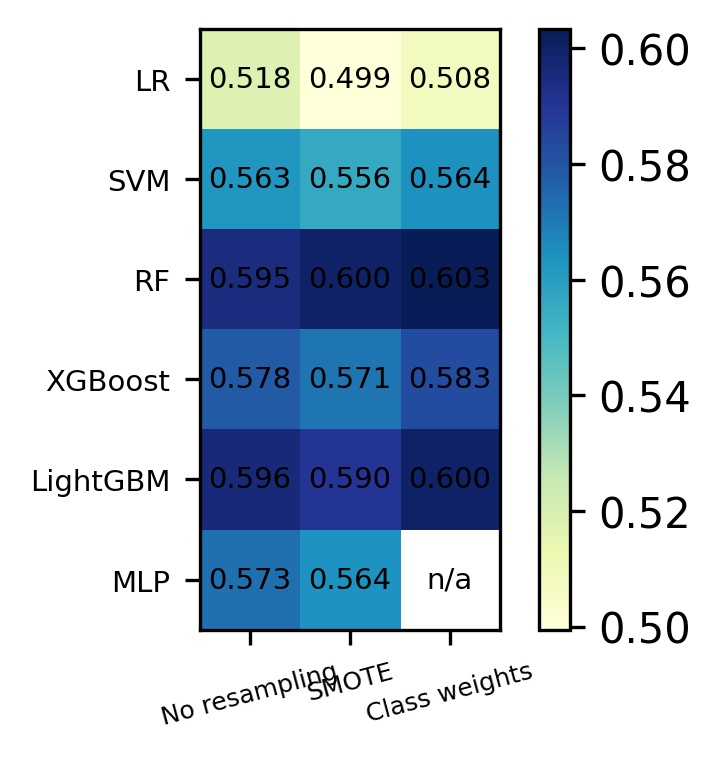

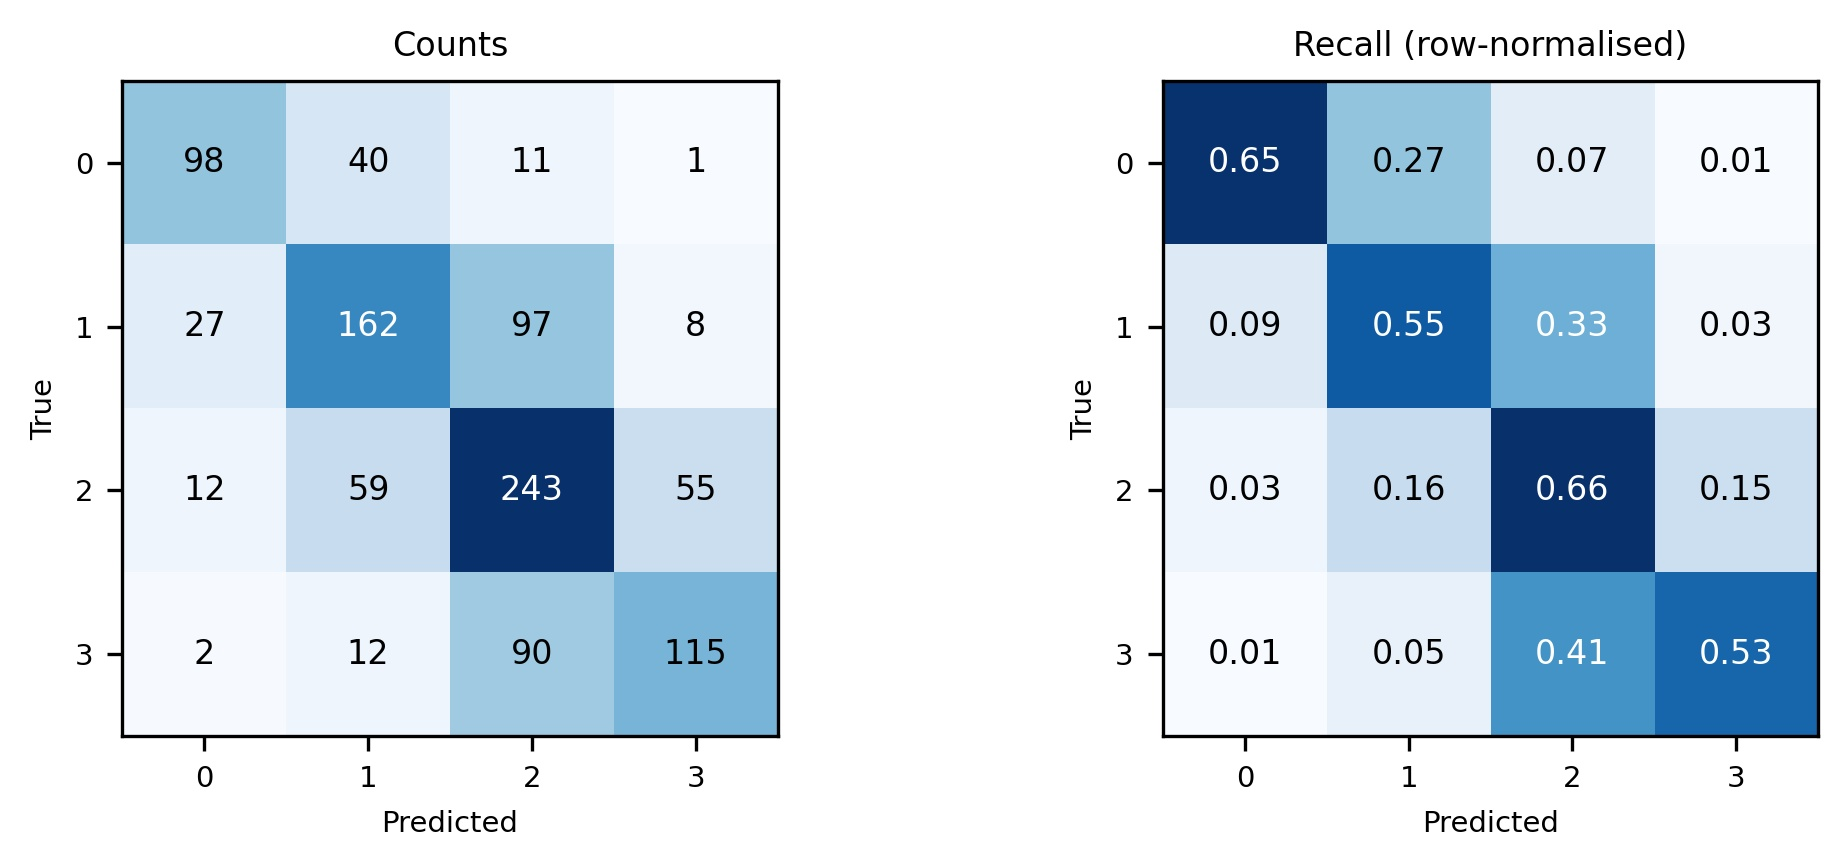

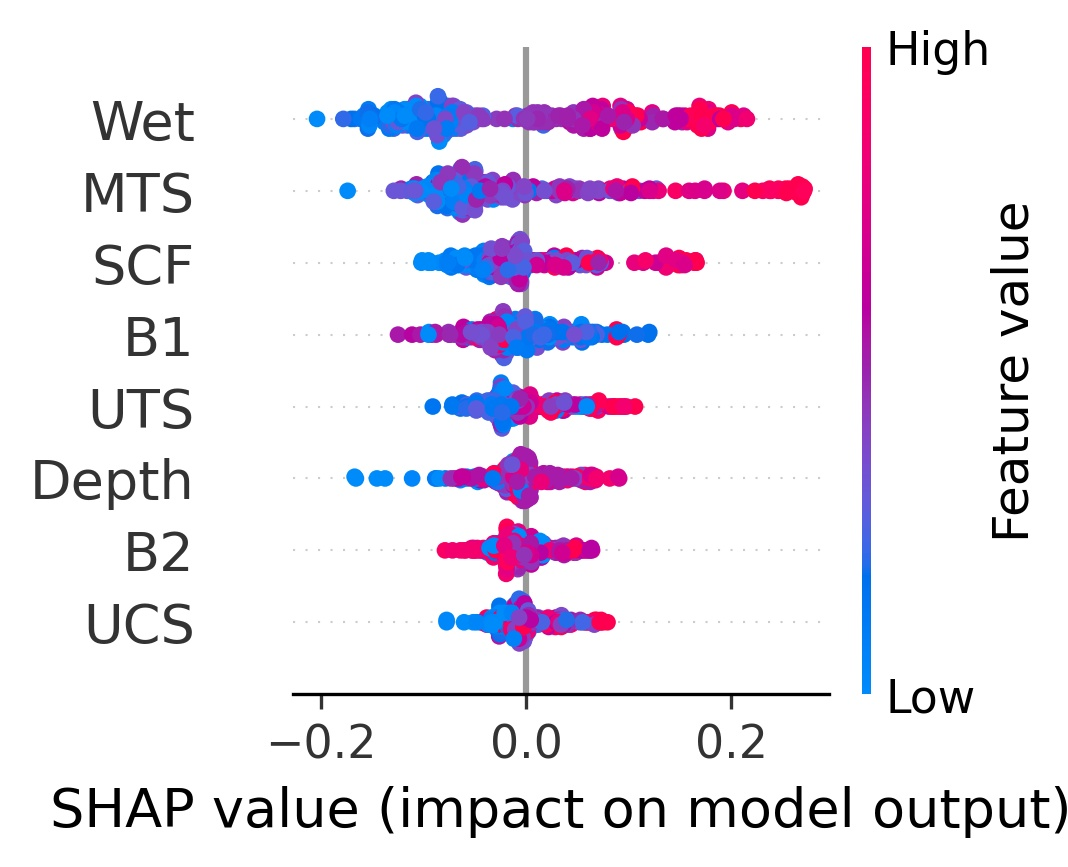

In [32]:
# 8. look at the results
display(pd.read_csv('outputs/summary.csv'))
from IPython.display import Image, display as d
for n in ['fig_heatmap_f1','fig_cm_best','fig_shap_beeswarm']:
    d(Image('outputs/figures/%s.jpg' % n, width=500))

In [35]:
# 9. build the Overleaf bundle and download it
import shutil, os
shutil.rmtree('bundle', ignore_errors=True); os.makedirs('bundle')
shutil.copy('main.tex', 'bundle/main.tex'); shutil.copy('outputs/auto_macros.tex', 'bundle/auto_macros.tex')
shutil.copytree('outputs/figures', 'bundle/figures'); shutil.copytree('outputs/tables', 'bundle/tables')
shutil.copy('fig_workflow.jpg', 'bundle/figures/fig_workflow.jpg')   # your Fig. 1
shutil.copy('outputs/summary.csv', 'bundle/summary.csv')
assert 'DEMO' not in open('bundle/auto_macros.tex').read(), 'demo data detected'
shutil.make_archive('overleaf_bundle', 'zip', 'bundle')
files.download('overleaf_bundle.zip')
shutil.make_archive('figures_jpeg', 'zip', 'bundle/figures'); files.download('figures_jpeg.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>